# Tópicos Avançados de Aprendizagem Máquina
#### Trabalho Prático de Processamento de Linguagem Natural

### Avaliação Experimental de Técnicas de Vetorização de Texto em Classificação Binária de Mensagens SMS


#### **Corpus**
Será utilizado o dataset SMS Spam Collection disponível no repositório UCI Machine Learning, o qual contém aproximadamente 5.000 mensagens SMS anotadas manualmente.

| **Carac.** | **Descrição** |
| :--- | :--- |
| **Fonte** | https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip |
| **Classes** |	spam (mensagens indesejadas) e ham (mensagens legítimas) |
| **Distribuição** | Desbalanceada (aproximadamente 13% spam, 87% ham) |
| **Tamanho** | ~5.000 mensagens |
| **Vantagens** | Tamanho moderado, desbalanceamento realista (13% spam), ideal para comparar representações. |

#### **Objetivos**
1. Avaliar o impacto do pré-processamento
2. Comparar eficácia de diferentes representações de texto
3. Avaliar desempenho relativo de modelos de classificação
4. Implementar pipeline modular reutilizável com scikit-learn
5. Aplicar técnicas de otimização de hiperparâmetros
6. Documentar e analisar resultados experimentais

#### **Nota**

A função `run_experiments` e a estrutura de configuração por listas de dicionários (`text_representations`, `classifiers`) do código base foram **mantidas e estendidas** (novos parâmetros opcionais, todos com valores por defeito que preservam o comportamento original), garantindo retrocompatibilidade. Mantém-se `random_state=42` / `seed=42` em todos os componentes que o suportam (requisito de reprodutibilidade).

## 1. Setup Inicial

Instalação de dependências e importação de bibliotecas necessárias.

In [ ]:
!pip install -q scikit-learn pandas numpy matplotlib seaborn nltk gensim imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 52.3 MB/s eta 0:00:00


In [ ]:
# Matplotlib configuration for Jupyter notebook
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re
import time
import string
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from gensim.models import Word2Vec, Doc2Vec
from gensim.models.doc2vec import TaggedDocument
from sklearn.base import BaseEstimator, TransformerMixin, clone

# NOVO: suporte a reamostragem (Tarefa T1 - Oversampling/Undersampling)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Download recursos NLTK (executar apenas uma vez)
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# Seeds para reprodutibilidade
np.random.seed(42)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


## 2. Carregar Dataset

Descarregamento e leitura do dataset SMS Spam Collection do UCI.

In [ ]:
import zipfile
import io
import urllib.request

# Descarregar o ficheiro zip do UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip"
print("Descarregando ficheiro zip...")
with urllib.request.urlopen(url) as response:
    zip_data = response.read()

# Abrir o zip em memória e listar os ficheiros
with zipfile.ZipFile(io.BytesIO(zip_data)) as zip_ref:
    file_list = zip_ref.namelist()
    print(f"Ficheiros no zip: {file_list}")

    # Procurar pelo ficheiro SMSSpamCollection
    data_file = [f for f in file_list if 'SMSSpamCollection' in f][0]
    print(f"Lendo ficheiro: {data_file}")

    # Ler o ficheiro directamente do zip
    with zip_ref.open(data_file) as f:
        df = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

Descarregando ficheiro zip...
Ficheiros no zip: ['SMSSpamCollection', 'readme']
Lendo ficheiro: SMSSpamCollection


### Exploração Inicial do Dataset

In [ ]:
print("Shape:", df.shape)
print("\nDistribuição das classes:")
print(df['label'].value_counts(normalize=True))

# Mapeamento label para binário
df['label_bin'] = df['label'].map({'ham': 0, 'spam': 1})

print("\nPrimeiras 5 mensagens:")
display(df.head())

Shape: (5572, 2)

Distribuição das classes:
label
ham     0.865937
spam    0.134063
Name: proportion, dtype: float64

Primeiras 5 mensagens:


,label,message,label_bin
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 3. Funções de Pré-processamento

Definição de funções para limpeza e processamento de texto com diferentes opções.

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text, do_lemmatize=True, remove_stopwords=True):
    """
    Limpa e processa texto.
    Args:
        text: string a processar
        do_lemmatize: aplicar lematização?
        remove_stopwords: remover stop words?
    Returns:
        string processada
    """
    # Lowercase
    text = text.lower()
    # Remover pontuação e números
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    # Tokenização
    tokens = word_tokenize(text)
    # Remover stop words (opcional)
    if remove_stopwords:
        tokens = [t for t in tokens if t not in stop_words]
    # Lematização (opcional)
    if do_lemmatize:
        tokens = [lemmatizer.lemmatize(t) for t in tokens]
    # Rejuntar
    return ' '.join(tokens)

### Aplicação do Pré-processamento

In [ ]:
# Criar duas versões do dataset
df['msg_clean_lemm_stop'] = df['message'].apply(
    lambda x: clean_text(x, do_lemmatize=True, remove_stopwords=True))
df['msg_clean_raw'] = df['message'].apply(
    lambda x: clean_text(x, do_lemmatize=False, remove_stopwords=False))

print("\nExemplo de processamento:")
print("Original:", df['message'].iloc[0][:100])
print("Lemmatized+stop:", df['msg_clean_lemm_stop'].iloc[0][:100])
print("Raw (só lower+limpeza):", df['msg_clean_raw'].iloc[0][:100])


Exemplo de processamento:
Original: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got a
Lemmatized+stop: go jurong point crazy available bugis n great world la e buffet cine got amore wat
Raw (só lower+limpeza): go until jurong point crazy available only in bugis n great world la e buffet cine there got amore w


### 3.1 Split treino/teste único (Config A vs Config B)

Para a Tarefa **T2** (impacto do pré-processamento), comparamos a Config A (`msg_clean_raw`: lowercase + remoção de pontuação) com a Config B (`msg_clean_lemm_stop`: stop words removidas + lematização).

In [ ]:
X_train_A, X_test_A, y_train, y_test = train_test_split(
    df['msg_clean_raw'], df['label_bin'],
    test_size=0.2, random_state=42, stratify=df['label_bin']
)
X_train_B, X_test_B, _, _ = train_test_split(
    df['msg_clean_lemm_stop'], df['label_bin'],
    test_size=0.2, random_state=42, stratify=df['label_bin']
)

X_train, X_test = X_train_B, X_test_B

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")
print(f"Spam ratio train: {y_train.mean():.2%} | test: {y_test.mean():.2%}")

Train size: 4457 | Test size: 1115
Spam ratio train: 13.42% | test: 13.36%


## 4. Técnicas de Representações de Texto a Testar

Implementação de diferentes técnicas de representação de texto:
- Bag of Words (BoW)
- TF-IDF
- Word2Vec
- Doc2Vec

#### Word2Vec e Doc2Vec Vectorizer - Adaptação para scikit-learn

Os modelos `Word2Vec` `Doc2Vec`do Gensim não são nativamente compatíveis com `scikit-learn`. Para integrar no `Pipeline` e usar com `GridSearchCV`, é necessário:

1. **Herdar de `BaseEstimator` e `TransformerMixin`** - Interface padrão do ``sklearn` para transformadores
2. **Implementar métodos `fit()` e `transform()`** - Contrato de transformação do `sklearn`
3. **Permitir hiperparâmetros no construtor** - Para que `GridSearchCV` possa otimizar `vector_size`, `min_count`, `epochs`, etc.
4. **Documentar o comportamento** - A representação retorna a **média dos vetores** das palavras de cada documento

Esta abordagem permite:
- Usar `Word2Vec` e `Doc2Vec` dentro de `Pipeline([('vect', Word2VecVectorizer()), ('clf', classifier)])`
- Testar combinações de hiperparâmetros com `GridSearchCV`
- Manter coerência com outros transformadores (`CountVectorizer`, `TfidfVectorizer`)
- Serializar e reutilizar modelos treinados

In [ ]:
class Word2VecVectorizer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, min_count=2, epochs=10):
        self.vector_size = vector_size
        self.min_count = min_count
        self.epochs = epochs
        self.model = None

    def fit(self, X, y=None):
        # Tokenizar sentenças
        tokenized = [text.split() for text in X]
        self.model = Word2Vec(sentences=tokenized,
                              vector_size=self.vector_size,
                              min_count=self.min_count,
                              epochs=self.epochs,
                              seed=42,     # reprodutibilidade (nota: com workers>1 o gensim
                                           # não garante 100% determinismo, mas o seed ajuda)
                              workers=4)
        #self.model.train(tokenized, total_examples=len(tokenized), epochs=self.epochs)
        return self

    def transform(self, X):
        tokenized = [text.split() for text in X]
        X_vec = []
        for tokens in tokenized:
            word_vectors = [self.model.wv[w] for w in tokens if w in self.model.wv]
            if len(word_vectors) == 0:
                X_vec.append(np.zeros(self.vector_size))
            else:
                X_vec.append(np.mean(word_vectors, axis=0))
        return np.array(X_vec)

In [ ]:
class Doc2VecVectorizer(BaseEstimator, TransformerMixin):
    def __init__(self, vector_size=100, epochs=20):
        self.vector_size = vector_size
        self.epochs = epochs
        self.model = None

    def fit(self, X, y=None):
        tokenized = [text.split() for text in X]
        tagged_docs = [TaggedDocument(doc, [i]) for i, doc in enumerate(tokenized)]
        self.model = Doc2Vec(vector_size=self.vector_size, epochs=self.epochs, min_count=2,
                              seed=42, workers=1)  # workers=1 necessário para reprodutibilidade do Doc2Vec
        self.model.build_vocab(tagged_docs)
        self.model.train(tagged_docs, total_examples=self.model.corpus_count, epochs=self.model.epochs)
        return self

    def transform(self, X):
        tokenized = [text.split() for text in X]
        return np.array([self.model.infer_vector(doc) for doc in tokenized])

### Configuração das Representação de Texto a Testar

A próxima célula define uma **lista de configurações** com 4 técnicas diferentes de vetorização de texto que irão ser testadas:

1. **BoW (Bag of Words)** - Contagem simples de palavras/bigramas
2. **TF-IDF** - Ponderação por frequência e inversa de documento
3. **Word2Vec** - Embeddings de palavras (média dos vectores)
4. **Doc2Vec** - Embeddings de documentos completos

Para cada representação, pode habilitar/desabilitar:
```python
'disable': False   # Habilitar (vai ser testada)
'disable': True    # Desabilitar (vai ser ignorada)
```

**Definir Hiperparâmetros a Testar:**
- Os valores entre parênteses `()` definem o **grid de busca**
- Todos os hiperparâmetros têm o prefixo `vect__`
- O `GridSearchCV` vai testar TODAS as combinações possíveis
- Exemplo: 3 valores × 2 valores = 6 combinações

**Exemplo de modificação:**
```python
'parameters': {
    'vect__max_df': (0.5, 0.75, 1.0),        # 3 valores
    'vect__ngram_range': ((1, 1), (1, 2))    # 2 valores
    # Total: 3 × 2 = 6 combinações
}
```

In [ ]:
text_representations = [
    {
        'name': 'BoW',
        'vect': CountVectorizer(min_df=2, max_features=4000),
        'parameters': {
            'vect__max_df': (0.5, 0.75, 1.0),
            'vect__ngram_range': ((1, 1), (1, 2))
        },
        'disable': False
    },
    {
        'name': 'TF-IDF',
        'vect': TfidfVectorizer(min_df=2, max_features=4000),
        'parameters': {
            # Grid reduzido (4 combinações em vez de 24): mantém os hiperparâmetros
            # mais informativos e simétricos ao BoW, fixando use_idf=True, norm='l2'
            'vect__max_df': (0.75, 1.0),
            'vect__ngram_range': ((1, 1), (1, 2))
        },
        'disable': False   # <- habilitado (T2/T3)
    },
    {
        'name': 'Word2Vec',
        'vect': Word2VecVectorizer(),
        'parameters': {
            # Grid reduzido: fixa epochs=20 (valor por defeito da classe)
            'vect__vector_size': (50, 100),
            'vect__min_count': (1, 2)
        },
        'disable': True   # usado explicitamente na Secção 6.2 (representações adicionais)
    },
    {
        'name': 'Doc2Vec',
        'vect': Doc2VecVectorizer(),
        'parameters': {
            'vect__vector_size': (50, 100)
        },
        'disable': True   # usado explicitamente na Secção 6.2
    }
]

## 5. Configuração dos Modelos de Classificação

A próxima célula define uma **lista de configurações** com 3 algoritmos de classificação diferentes:

1. **Logistic Regression** - Modelo linear probabilístico
3. **SVM (linear)** - Máquina de vetores de suporte
4. **Random Forest** - Ensemble de árvores de decisão

Para cada classificador, pode **Habilitar/Desabilitar**:
```python
'disable': False   # Habilitar (vai ser testado)
'disable': True    # Desabilitar (vai ser ignorado)
```

**Definir Hiperparâmetros a Testar:**
- Os valores entre parênteses `()` definem o **grid de busca**
- Todos os hiperparâmetros deverão ter o prefixo `clf__`
- O `GridSearchCV` vai testar TODAS as combinações possíveis
- Exemplo para Logistic Regression: 3 valores de C × 2 tipos de penalty = 6 combinações

**Exemplo de modificação:**
```python
'parameters': {
    'clf__C': (0.1, 1, 10),                 # 3 valores
    'clf__penalty': ('l2', 'elasticnet')    # 2 valores
    # Total: 3 × 2 = 6 combinações
}
```

In [ ]:
classifiers = [
    {
        'name': 'Logistic Regression',
        'clf': LogisticRegression(random_state=42, max_iter=1000),
        'parameters': {
            # Grid simplificado: 'penalty': 'elasticnet' exige solver='saga' + l1_ratio,
            # o que falha (NaN) com o solver por defeito ('lbfgs'). Mantém-se
            # apenas o grid de C, o hiperparâmetro mais relevante aqui.
            'clf__C': (0.1, 1, 10)
        },
        'disable': False
    },
    {
        'name': 'SVM (linear)',
        'clf': SVC(random_state=42),
        'parameters': {
            'clf__kernel': ['linear', 'rbf'],
            'clf__C': (0.1, 1, 10)
        },
        'disable': False   # <- habilitado (T3)
    },
    {
        'name': 'Random Forest',
        'clf': RandomForestClassifier(random_state=42),
        'parameters': {
            'clf__n_estimators': (100, 200),
            'clf__max_depth': (None, 10, 20)
        },
        'disable': False   # <- habilitado (T3)
    },
    # adicionar mais classificadores aqui
]

## 6. Executar Experimentos

Esta secção executa uma **análise experimental completa** que:

1. **Combina representações com classificadores**: Testa todas as combinações habilitadas de técnicas de vetorização (BoW, TF-IDF, Word2Vec, Doc2Vec) com diferentes algoritmos de classificação (Logistic Regression, SVM, Random Forest).

2. **Otimiza hiperparâmetros**: Para cada combinação, utiliza `GridSearchCV` com validação cruzada 5-fold para encontrar os melhores parâmetros.

3. **Avalia em diferentes conjuntos**:
   - **Validação cruzada**: Mede o desempenho durante a otimização
   - **Conjunto de teste**: Avalia o desempenho em dados não vistos

4. **Calcula múltiplas métricas**: Accuracy e F1-score para detectar desempenho e desbalanceamento.

5. **Armazena resultados**: Guarda informações de cada experimento (parâmetros, scores, tempo) para análise posterior.

#### Tempo de execução esperado

Depende do número de representações e classificadores habilitados:
- **Rápido** (BoW + Logistic Regression): ~10-20 segundos
- **Rápido** (BoW + TF-IDF + Logistic Regression): ~1-2 minutos
- **Rápido** (BoW + TF-IDF + Logistic Regression + SVC): ~6-7 minutos
- **Moderado** (Word2Vec + Logistic Regression + SVC + Random Forest): ~13-15 minutos
- **Moderado** (BoW + TF-IDF + + Logistic Regression + SVC + Random Forest): ~20-25 minutos
- **Completo** (4 representações + 3 classificadores): ~45-50 minutos

---
**Nota:** `run_experiments` ganhou dois parâmetros opcionais (valores por defeito reproduzem o comportamento original):
- `sampler`: técnica de reamostragem `imblearn` (T1) — quando definida, usa `imblearn.pipeline.Pipeline` em vez de `sklearn.pipeline.Pipeline`, aplicando o resampling apenas ao treino de cada fold (sem fuga de dados).
- `preprocessing_label`: rótulo descritivo (T2), guardado em cada resultado para permitir comparar Config A vs Config B na tabela final.

In [ ]:
def run_experiments(text_representations, classifiers, X_train, y_train, X_test, y_test,
                     sampler=None, preprocessing_label='lemm_stop'):
    """
    Executa uma série de experimentos combinando diferentes representações de texto
    com vários classificadores, aplicando GridSearchCV para otimização de hiperparâmetros.

    Parameters
    ----------
    text_representations : list of dict
        Lista de configurações de representações de texto.
        Cada dicionário contém:
        - 'name': str - Nome descritivo da representação (ex: 'BoW', 'TF-IDF', 'Word2Vec')
        - 'vect': sklearn transformer - Vetorizador de texto
        - 'parameters': dict - Parâmetros a testar (com prefixo 'vect__')
        - 'disable': bool - Se True, representa não é testada

    classifiers : list of dict
        Lista de configurações de classificadores.
        Cada dicionário contém:
        - 'name': str - Nome descritivo do classificador (ex: 'Logistic Regression', 'SVM')
        - 'clf': sklearn classifier - Modelo de classificação
        - 'parameters': dict - Parâmetros a testar (com prefixo 'clf__')
        - 'disable': bool - Se True, classificador não é testado

    X_train : array-like of shape (n_samples, )
        Dados de treino (texto pré-processado).

    y_train : array-like of shape (n_samples, )
        Rótulos de classe para treino (0 = ham, 1 = spam).

    X_test : array-like of shape (n_samples, )
        Dados de teste (texto pré-processado).

    y_test : array-like of shape (n_samples, )
        Rótulos de classe para teste (0 = ham, 1 = spam).

    sampler : imblearn sampler ou None, default=None
        Técnica de reamostragem (ex.: SMOTE(random_state=42), RandomUnderSampler(random_state=42))
        a aplicar APENAS ao conjunto de treino, dentro de cada fold da validação cruzada
        (Tarefa T1). Se None, não é feito balanceamento (baseline desbalanceado).
        Quando 'sampler' não é None, o pipeline passa a ser um imblearn.pipeline.Pipeline
        (em vez de sklearn.pipeline.Pipeline), que é o único que suporta passos de
        reamostragem (fit_resample) de forma segura com GridSearchCV / cross-validation
        (o resampling nunca é aplicado ao conjunto de validação/teste -> sem fuga de dados).

    preprocessing_label : str, default='lemm_stop'
        Rótulo meramente descritivo da versão de pré-processamento usada (Tarefa T2),
        guardado em cada resultado para permitir filtrar/comparar na tabela final
        (ex.: 'raw' para Config A - lowercase + remoção de pontuação;
              'lemm_stop' para Config B - + stop words + lematização).

    Returns
    -------
    experiments : list of dict
        Lista de resultados de cada experimento realizado.
        Cada dicionário contém:
        - 'model': str - Nome do classificador usado
        - 'vect': str - Nome da representação de texto usada
        - 'preprocessing': str - Rótulo da versão de pré-processamento usada (NOVO)
        - 'sampler': str - Nome da técnica de reamostragem usada, ou 'None' (NOVO)
        - 'params': dict - Melhores parâmetros encontrados
        - 'cv_accuracy': float - Accuracy médio em validação cruzada
        - 'cv_f1': float - F1-score médio em validação cruzada
        - 'test_accuracy': float - Accuracy no conjunto de teste
        - 'test_f1': float - F1-score no conjunto de teste
        - 'num_combinations': int - Número de combinações de hiperparâmetros testadas
        - 'execution_time': float - Tempo de execução em segundos

    Notes
    -----
    - Usa GridSearchCV com validação cruzada 5-fold
    - Otimiza para F1-score (refit='f1')
    - Testa todas as combinações habilitadas de representações × classificadores
    - Mostra matriz de confusão para cada experimento
    - Calcula automaticamente número de combinações a testar
    - Usa todos os cores disponíveis (n_jobs=-1)
    - Quando 'sampler' é fornecido, o passo de reamostragem é incluído no pipeline
      (imblearn.pipeline.Pipeline) e só atua sobre os dados de treino de cada fold

    Example
    -------
    >>> results = run_experiments(
    ...     text_representations=text_reps,
    ...     classifiers=classifiers,
    ...     X_train=X_train,
    ...     y_train=y_train,
    ...     X_test=X_test,
    ...     y_test=y_test,
    ...     sampler=SMOTE(random_state=42),
    ...     preprocessing_label='lemm_stop'
    ... )
    >>> results_df = pd.DataFrame(results)
    """

    print("Iniciando experimentos combinando representações de texto e classificadores...")

    text_representations_filtered = [rep for rep in text_representations if not rep.get('disable', False)]
    print("Modelos de representação de texto:", [rep['name'] for rep in text_representations_filtered])

    classifiers_filtered = [clf for clf in classifiers if clf.get('disable', False) == False]
    print("Modelos de classificação:", [clf['name'] for clf in classifiers_filtered])

    sampler_name = sampler.__class__.__name__ if sampler is not None else 'None'
    print(f"Pré-processamento: {preprocessing_label} | Reamostragem: {sampler_name}")

    # Lista para armazenar resultados de todos os experimentos
    experiments = []

    # Cronometrar tempo total de execução
    start_time_total = time.time()

    # Iterar sobre cada representação de texto configurada
    for representation in text_representations_filtered:
        # Para cada representação, iterar sobre todos os classificadores
        for classifier in classifiers_filtered:
            # Informações do experimento atual
            print(f"\n=== Experimento {len(experiments) + 1}: {classifier['name']} com {representation['name']} "
                  f"[{preprocessing_label} | {sampler_name}] ===")
            print(f"  Parâmetros a testar (classificador): {classifier['parameters']}")
            print(f"  Parâmetros a testar (representação): {representation['parameters']}")

            # Criar um pipeline que combina vetorização + (reamostragem opcional) + classificação
            # Ordem: texto -> vetorizador -> [reamostragem] -> classificador
            if sampler is None:
                pipeline = Pipeline([
                    ('vect', representation['vect']),
                    ('clf', classifier['clf'])
                ])
            else:
                # imblearn.pipeline.Pipeline: o passo 'sampler' só atua em fit()
                # (treino de cada fold), nunca em transform()/predict() -> sem fuga de dados
                pipeline = ImbPipeline([
                    ('vect', representation['vect']),
                    ('sampler', clone(sampler)),
                    ('clf', classifier['clf'])
                ])

            # Combinar parâmetros do classificador e da representação para GridSearch
            # Prefixo 'clf__' para parâmetros do classificador, 'vect__' para a vetorização
            parameters = {**classifier['parameters'], **representation['parameters']}

            # Calcular número de combinações que serão testadas
            num_combinations = 1
            for param_values in parameters.values():
                if isinstance(param_values, (list, tuple)):
                    num_combinations *= len(param_values)

            print(f"  Número de combinações a testar: {num_combinations} (com 5-fold CV = {num_combinations * 5} treinos)")

            # Cronometrar tempo deste experimento
            start_time_exp = time.time()

            # GridSearchCV testa todas as combinações de parâmetros com validação cruzada
            grid_search = GridSearchCV(
                pipeline,                     # Pipeline a otimizar
                parameters,                   # Parâmetros a testar
                n_jobs=-1,                    # Usar todos os cores do processador
                verbose=0,                    # Não mostrar detalhes da busca
                cv=5,                         # 5-fold cross-validation
                scoring=['accuracy', 'f1'],   # Métricas a calcular
                refit='f1'                    # Usar F1-score para escolher melhor modelo
            )

            # Treinar o modelo testando todas as combinações de parâmetros
            grid_search.fit(X_train, y_train)

            # Parar cronometro do experimento
            elapsed_time_exp = time.time() - start_time_exp
            elapsed_time_total = time.time() - start_time_total

            # Avaliar o melhor modelo no conjunto de teste (dados não vistos)
            y_pred_test = grid_search.predict(X_test)
            test_accuracy = accuracy_score(y_test, y_pred_test)
            test_f1 = f1_score(y_test, y_pred_test)

            # Extrair resultados da melhor combinação encontrada em validação cruzada
            best_idx = grid_search.best_index_
            best_params = grid_search.cv_results_['params'][best_idx]
            best_cv_accuracy = grid_search.cv_results_['mean_test_accuracy'][best_idx]
            best_cv_f1 = grid_search.cv_results_['mean_test_f1'][best_idx]

            # Mostrar melhores parâmetros encontrados
            print("\n  Melhores parâmetros:", best_params)
            print(f"\n  Melhor pontuação (validação cruzada):")
            print(f"      F1: {best_cv_f1:.3f}")
            print(f"      Accuracy: {best_cv_accuracy:.3f}")

            # Mostrar desempenho no conjunto de teste
            print(f"\n  Melhor pontuação (teste):")
            print(f"      F1: {test_f1:.3f}")
            print(f"      Accuracy: {test_accuracy:.3f}")

            # Matriz de confusão
            cm = confusion_matrix(y_test, y_pred_test)
            sns.heatmap(cm, annot=True, fmt='d')
            plt.title(f'Confusion Matrix - {classifier["name"]} with {representation["name"]} '
                      f'[{preprocessing_label} | {sampler_name}]')
            plt.show()

            # Mostrar tempo de execução
            print(f"\n  Tempo de execução do experimento: {elapsed_time_exp:.0f}\" ({elapsed_time_exp/60:.2f}') / total: {elapsed_time_total:.0f}\" ({elapsed_time_total/60:.2f}')")

            # Guardar resultados deste experimento para análise posterior
            experiments.append({
                'model': classifier['name'],
                'vect': representation['name'],
                'preprocessing': preprocessing_label,
                'sampler': sampler_name,
                'params': best_params,
                'cv_accuracy': best_cv_accuracy,
                'cv_f1': best_cv_f1,
                'test_accuracy': test_accuracy,
                'test_f1': test_f1,
                'num_combinations': num_combinations,
                'execution_time': elapsed_time_exp
            })

    # Parar cronometro total
    elapsed_time_total = time.time() - start_time_total

    # Mostrar resumo de tempo total
    print("\n" + "="*80)
    print("  RESUMO DE TEMPO DE EXECUÇÃO")
    print("="*80)

    total_combinations = sum([exp['num_combinations'] for exp in experiments])
    print(f"\nTotal de experimentos: {len(experiments)}")
    print(f"Total de combinações testadas: {total_combinations}")
    print(f"Total de modelos treinados: {total_combinations * 5} (com 5-fold CV)")
    print(f"\nTempo total de execução: {elapsed_time_total:.0f}\" ({elapsed_time_total/60:.2f}')")
    print(f"Tempo médio por experimento: {elapsed_time_total/len(experiments):.0f}\" ({(elapsed_time_total/len(experiments))/60:.2f}')")

    print("="*80 + "\n")

    return experiments

### 6.1 Tarefa T2 — Impacto do Pré-processamento (Config A vs Config B)

Esta secção executa `run_experiments` para **ambas** as configurações de pré-processamento definidas na Secção 3.1:

- **Config A** (`raw`): apenas lowercase + remoção de pontuação (`X_train_A`/`X_test_A`)
- **Config B** (`lemm_stop`): + remoção de stop words + lematização (`X_train_B`/`X_test_B`)

usando as representações **BoW** e **TF-IDF** e os três classificadores habilitados: **Logistic Regression, SVM (linear/rbf) e Random Forest**.

Combinações: 2 configs × 2 representações × 3 classificadores = **12** experimentos.


################################################################################
# T2 - Config A (raw): lowercase + remoção de pontuação
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['BoW', 'TF-IDF']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: raw | Reamostragem: None

=== Experimento 1: Logistic Regression com BoW [raw | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 18 (com 5-fold CV = 90 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__max_df': 0.5, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.926
      Accuracy: 0.981

  Melhor pontuação (teste):
      F1: 0.936
 

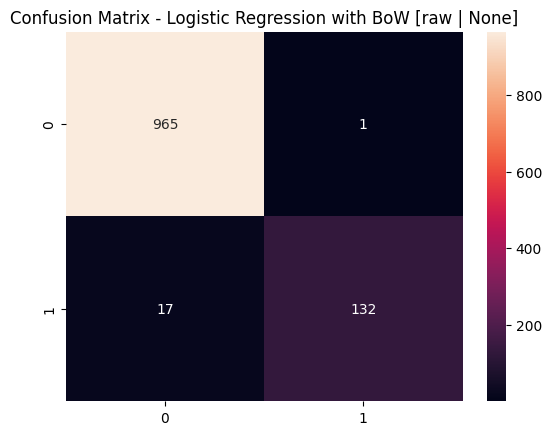


  Tempo de execução do experimento: 16" (0.27') / total: 16" (0.27')

=== Experimento 2: SVM (linear) com BoW [raw | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 36 (com 5-fold CV = 180 treinos)

  Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'linear', 'vect__max_df': 0.5, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.922
      Accuracy: 0.980

  Melhor pontuação (teste):
      F1: 0.931
      Accuracy: 0.982


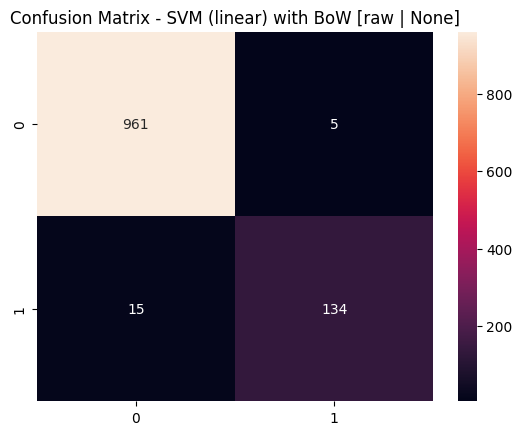


  Tempo de execução do experimento: 134" (2.24') / total: 151" (2.51')

=== Experimento 3: Random Forest com BoW [raw | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 36 (com 5-fold CV = 180 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.5, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.899
      Accuracy: 0.975

  Melhor pontuação (teste):
      F1: 0.916
      Accuracy: 0.979


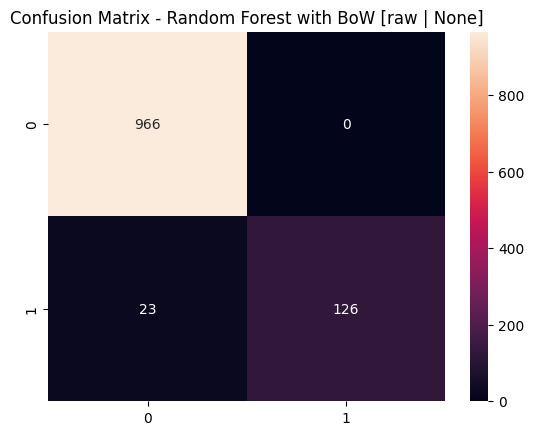


  Tempo de execução do experimento: 179" (2.98') / total: 330" (5.49')

=== Experimento 4: Logistic Regression com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.931
      Accuracy: 0.982

  Melhor pontuação (teste):
      F1: 0.929
      Accuracy: 0.982


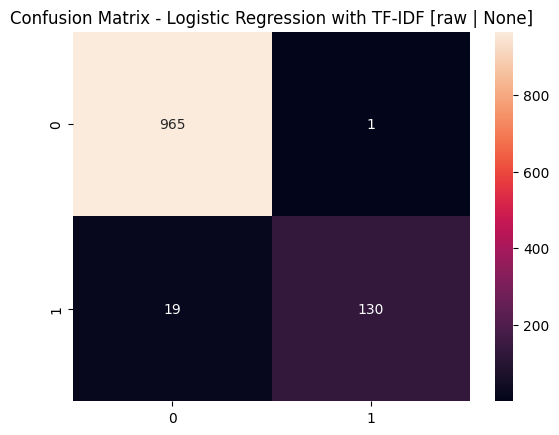


  Tempo de execução do experimento: 10" (0.17') / total: 340" (5.67')

=== Experimento 5: SVM (linear) com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'linear', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.938
      Accuracy: 0.984

  Melhor pontuação (teste):
      F1: 0.937
      Accuracy: 0.984


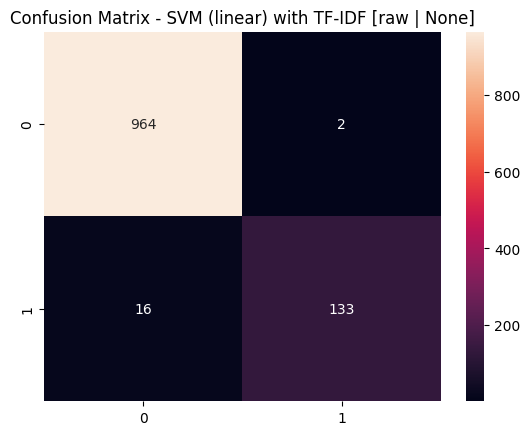


  Tempo de execução do experimento: 105" (1.75') / total: 445" (7.42')

=== Experimento 6: Random Forest com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.902
      Accuracy: 0.976

  Melhor pontuação (teste):
      F1: 0.871
      Accuracy: 0.970


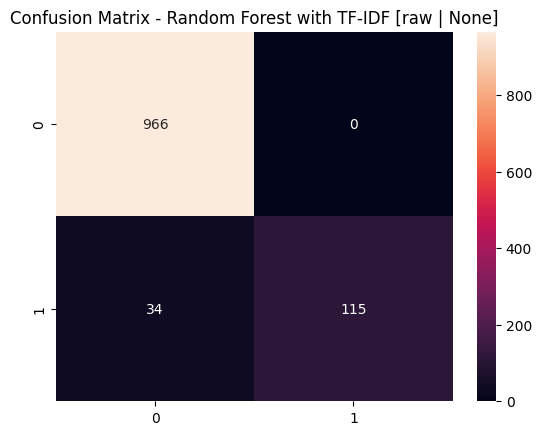


  Tempo de execução do experimento: 139" (2.31') / total: 584" (9.73')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 6
Total de combinações testadas: 150
Total de modelos treinados: 750 (com 5-fold CV)

Tempo total de execução: 584" (9.74')
Tempo médio por experimento: 97" (1.62')



In [ ]:
print("\n" + "#"*80)
print("# T2 - Config A (raw): lowercase + remoção de pontuação")
print("#"*80)
experiments_A = run_experiments(
    text_representations, classifiers,
    X_train_A, y_train, X_test_A, y_test,
    sampler=None, preprocessing_label='raw'
)


################################################################################
# T2 - Config B (lemm_stop): + stop words removidas + lematização
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['BoW', 'TF-IDF']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: lemm_stop | Reamostragem: None

=== Experimento 1: Logistic Regression com BoW [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 18 (com 5-fold CV = 90 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__max_df': 0.5, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.921
      Accuracy: 0.980

  Melhor pontuação (tes

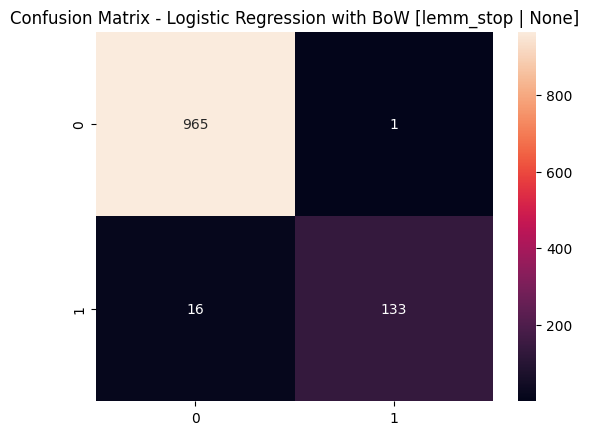


  Tempo de execução do experimento: 12" (0.21') / total: 12" (0.21')

=== Experimento 2: SVM (linear) com BoW [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 36 (com 5-fold CV = 180 treinos)

  Melhores parâmetros: {'clf__C': 10, 'clf__kernel': 'rbf', 'vect__max_df': 0.5, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.919
      Accuracy: 0.980

  Melhor pontuação (teste):
      F1: 0.918
      Accuracy: 0.979


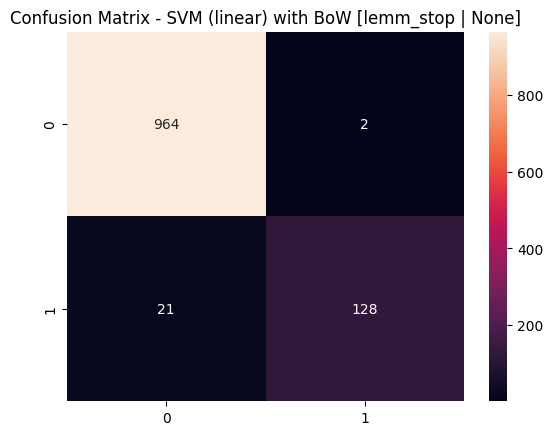


  Tempo de execução do experimento: 103" (1.71') / total: 115" (1.92')

=== Experimento 3: Random Forest com BoW [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.5, 0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 36 (com 5-fold CV = 180 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.5, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.905
      Accuracy: 0.976

  Melhor pontuação (teste):
      F1: 0.900
      Accuracy: 0.976


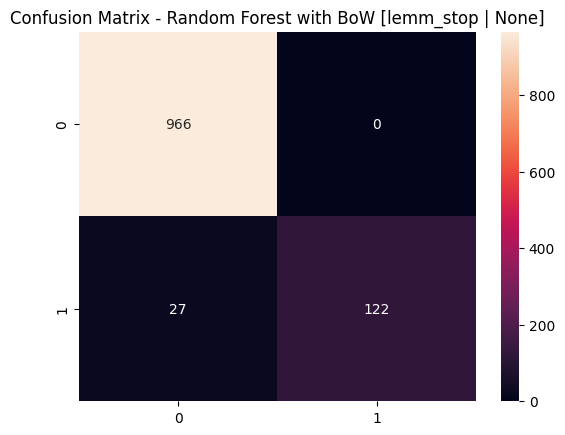


  Tempo de execução do experimento: 188" (3.14') / total: 304" (5.07')

=== Experimento 4: Logistic Regression com TF-IDF [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.921
      Accuracy: 0.980

  Melhor pontuação (teste):
      F1: 0.929
      Accuracy: 0.982


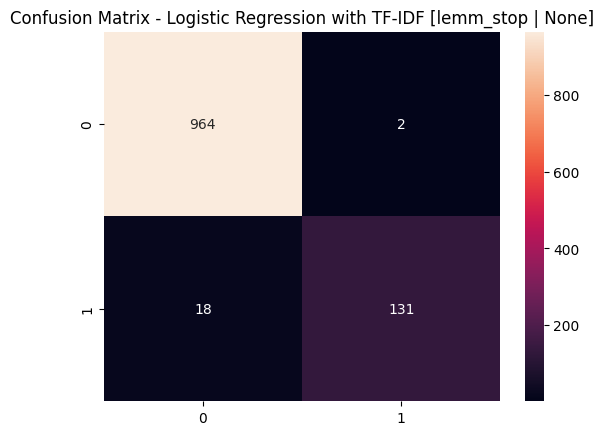


  Tempo de execução do experimento: 6" (0.11') / total: 311" (5.19')

=== Experimento 5: SVM (linear) com TF-IDF [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'linear', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.928
      Accuracy: 0.982

  Melhor pontuação (teste):
      F1: 0.926
      Accuracy: 0.981


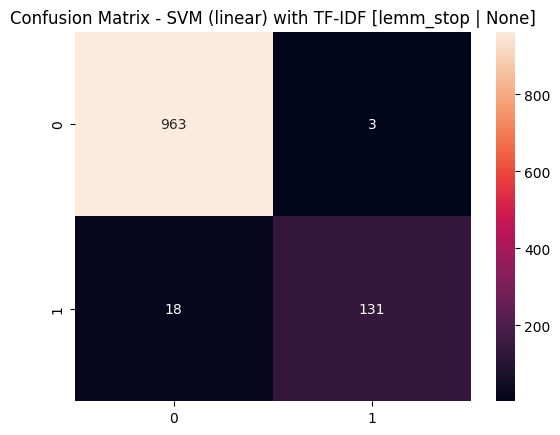


  Tempo de execução do experimento: 99" (1.64') / total: 410" (6.83')

=== Experimento 6: Random Forest com TF-IDF [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 100, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.901
      Accuracy: 0.976

  Melhor pontuação (teste):
      F1: 0.908
      Accuracy: 0.978


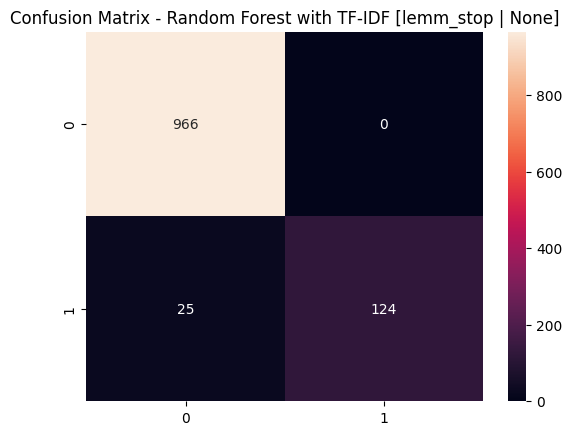


  Tempo de execução do experimento: 132" (2.21') / total: 543" (9.04')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 6
Total de combinações testadas: 150
Total de modelos treinados: 750 (com 5-fold CV)

Tempo total de execução: 543" (9.05')
Tempo médio por experimento: 90" (1.51')



In [ ]:
print("\n" + "#"*80)
print("# T2 - Config B (lemm_stop): + stop words removidas + lematização")
print("#"*80)
experiments_B = run_experiments(
    text_representations, classifiers,
    X_train_B, y_train, X_test_B, y_test,
    sampler=None, preprocessing_label='lemm_stop'
)


In [ ]:
experiments_t2 = experiments_A + experiments_B
print(f"\nTotal de experimentos T2 (Config A + Config B): {len(experiments_t2)}")


Total de experimentos T2 (Config A + Config B): 12


### 6.2 Tarefa T3 (continuação) — Representações Word2Vec e Doc2Vec

Para completar a comparação de representações pedida em T3, esta secção testa **Word2Vec** e **Doc2Vec** (Secção 4) sobre a Config B (`lemm_stop`, a versão de pré-processamento mais elaborada), combinadas com **Logistic Regression**, **SVM (linear/rbf)** e **Random Forest**.

Combinações: 2 representações × 3 classificadores = **6** experimentos adicionais.

In [ ]:
# Cópias das representações de embeddings, habilitadas apenas para esta secção
text_representations_emb = [
    {
        'name': 'Word2Vec',
        'vect': Word2VecVectorizer(),
        'parameters': {
            'vect__vector_size': (50, 100),
            'vect__min_count': (1, 2)
        },
        'disable': False
    },
    {
        'name': 'Doc2Vec',
        'vect': Doc2VecVectorizer(),
        'parameters': {
            'vect__vector_size': (50, 100)
        },
        'disable': False
    }
]



################################################################################
# T3 - Word2Vec / Doc2Vec (Config B) com Logistic Regression e SVM
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['Word2Vec', 'Doc2Vec']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: lemm_stop | Reamostragem: None

=== Experimento 1: Logistic Regression com Word2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100), 'vect__min_count': (1, 2)}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__min_count': 2, 'vect__vector_size': 50}

  Melhor pontuação (validação cruzada):
      F1: 0.721
      Accuracy: 0.936

  Melhor pontuação (teste):


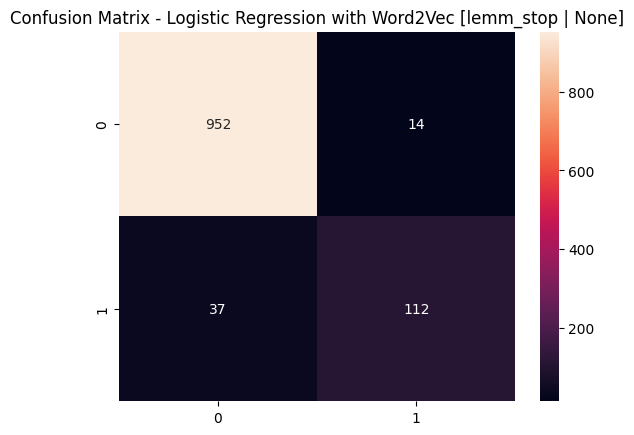


  Tempo de execução do experimento: 64" (1.06') / total: 64" (1.06')

=== Experimento 2: SVM (linear) com Word2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100), 'vect__min_count': (1, 2)}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 10, 'clf__kernel': 'rbf', 'vect__min_count': 2, 'vect__vector_size': 50}

  Melhor pontuação (validação cruzada):
      F1: 0.764
      Accuracy: 0.943

  Melhor pontuação (teste):
      F1: 0.837
      Accuracy: 0.959


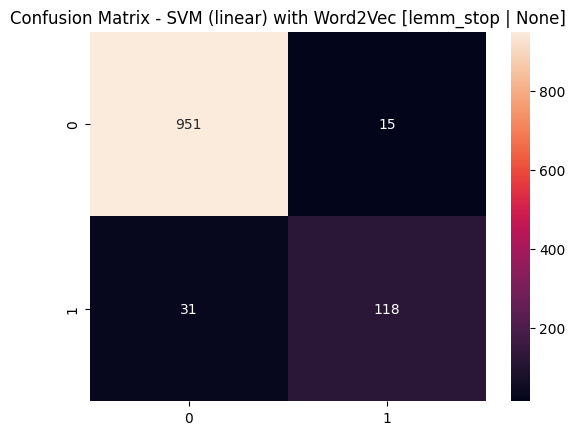


  Tempo de execução do experimento: 155" (2.58') / total: 219" (3.65')

=== Experimento 3: Random Forest com Word2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100), 'vect__min_count': (1, 2)}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__min_count': 2, 'vect__vector_size': 100}

  Melhor pontuação (validação cruzada):
      F1: 0.846
      Accuracy: 0.961

  Melhor pontuação (teste):
      F1: 0.873
      Accuracy: 0.968


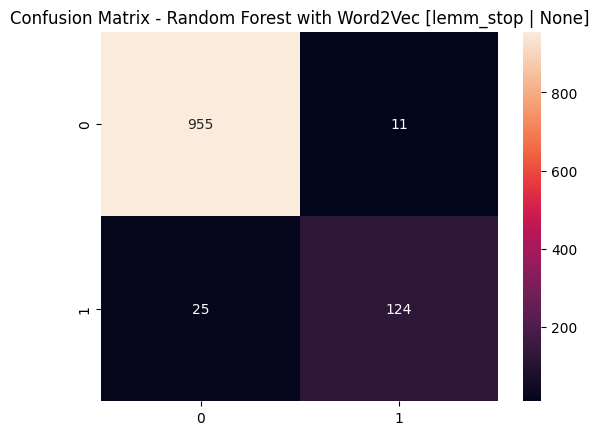


  Tempo de execução do experimento: 579" (9.66') / total: 799" (13.31')

=== Experimento 4: Logistic Regression com Doc2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100)}
  Número de combinações a testar: 6 (com 5-fold CV = 30 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__vector_size': 50}

  Melhor pontuação (validação cruzada):
      F1: 0.875
      Accuracy: 0.969

  Melhor pontuação (teste):
      F1: 0.798
      Accuracy: 0.952


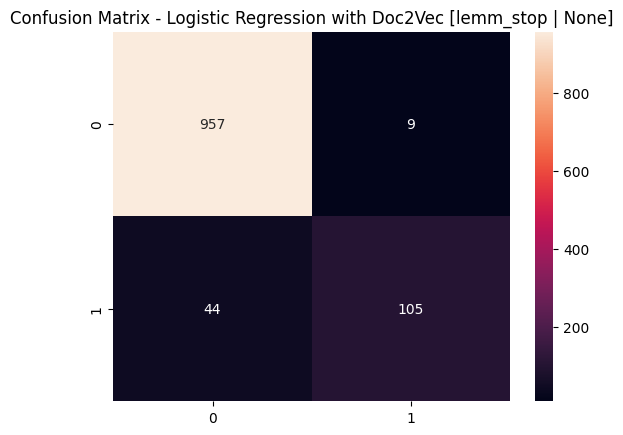


  Tempo de execução do experimento: 260" (4.34') / total: 1059" (17.65')

=== Experimento 5: SVM (linear) com Doc2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100)}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__C': 10, 'clf__kernel': 'rbf', 'vect__vector_size': 50}

  Melhor pontuação (validação cruzada):
      F1: 0.889
      Accuracy: 0.972

  Melhor pontuação (teste):
      F1: 0.863
      Accuracy: 0.967


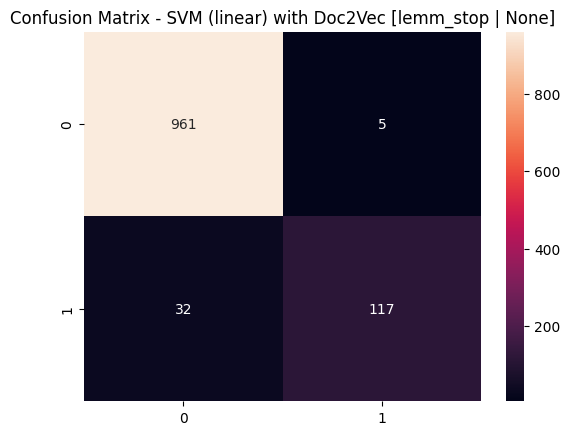


  Tempo de execução do experimento: 509" (8.49') / total: 1569" (26.16')

=== Experimento 6: Random Forest com Doc2Vec [lemm_stop | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__vector_size': (50, 100)}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__vector_size': 50}

  Melhor pontuação (validação cruzada):
      F1: 0.890
      Accuracy: 0.972

  Melhor pontuação (teste):
      F1: 0.843
      Accuracy: 0.962


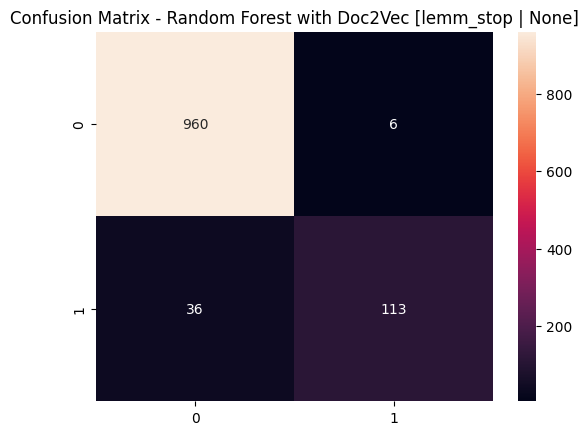


  Tempo de execução do experimento: 778" (12.97') / total: 2349" (39.15')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 6
Total de combinações testadas: 90
Total de modelos treinados: 450 (com 5-fold CV)

Tempo total de execução: 2351" (39.18')
Tempo médio por experimento: 392" (6.53')


Total de experimentos T3 (Word2Vec/Doc2Vec): 6


In [ ]:
print("\n" + "#"*80)
print("# T3 - Word2Vec / Doc2Vec (Config B) com Logistic Regression e SVM")
print("#"*80)
experiments_t3_emb = run_experiments(
    text_representations_emb, classifiers,
    X_train_B, y_train, X_test_B, y_test,
    sampler=None, preprocessing_label='lemm_stop'
)

print(f"\nTotal de experimentos T3 (Word2Vec/Doc2Vec): {len(experiments_t3_emb)}")

In [ ]:
# Visualizar as melhores combinações
pd.concat([pd.DataFrame(experiments_t2), pd.DataFrame(experiments_t3_emb)]).sort_values('test_f1', ascending=False)[['model', 'vect', 'preprocessing', 'cv_f1', 'test_f1']].head(10)

,model,vect,preprocessing,cv_f1,test_f1
6,Logistic Regression,BoW,lemm_stop,0.920945,0.939929
4,SVM (linear),TF-IDF,raw,0.938090,0.936620
0,Logistic Regression,BoW,raw,0.925952,0.936170
1,SVM (linear),BoW,raw,0.922365,0.930556
9,Logistic Regression,TF-IDF,lemm_stop,0.921401,0.929078
3,Logistic Regression,TF-IDF,raw,0.931288,0.928571
10,SVM (linear),TF-IDF,lemm_stop,0.928388,0.925795
7,SVM (linear),BoW,lemm_stop,0.918550,0.917563
2,Random Forest,BoW,raw,0.898722,0.916364
11,Random Forest,TF-IDF,lemm_stop,0.901256,0.908425


### 6.3 Tarefa T1 — Oversampling / Undersampling

O dataset SMS Spam é desbalanceado (~13% spam / 87% ham). Esta secção compara, para a representação **TF-IDF** sobre a **Config A** (raw) três estratégias de balanceamento:

1. **Baseline** — sem balanceamento (`sampler=None`)
2. **SMOTE** — oversampling sintético da classe minoritária (spam)
3. **RandomUnderSampler** — undersampling aleatório da classe maioritária (ham)

com os três classificadores habilitados: Logistic Regression, SVM e Random Forest.

A reamostragem é aplicada **apenas ao conjunto de treino de cada fold** (via `imblearn.pipeline.Pipeline`), nunca ao conjunto de teste — garantindo uma avaliação realista e sem fuga de dados.

Combinações: 1 representação × 3 classificadores × 3 estratégias de reamostragem = **9** experimentos.

> Nota: o caso "Baseline" (TF-IDF + Config A, sem reamostragem) repete uma configuração já testada em 6.1; mantém-se aqui para que a comparação T1 fique completa numa única tabela/gráfico, sem necessidade de ir buscar valores a outra secção.


################################################################################
# T1 - TF-IDF (Config A) + reamostragem: None
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['TF-IDF']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: raw | Reamostragem: None

=== Experimento 1: Logistic Regression com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 12 (com 5-fold CV = 60 treinos)

  Melhores parâmetros: {'clf__C': 10, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.931
      Accuracy: 0.982

  Melhor pontuação (teste):
      F1: 0.929
      Accuracy: 0.9

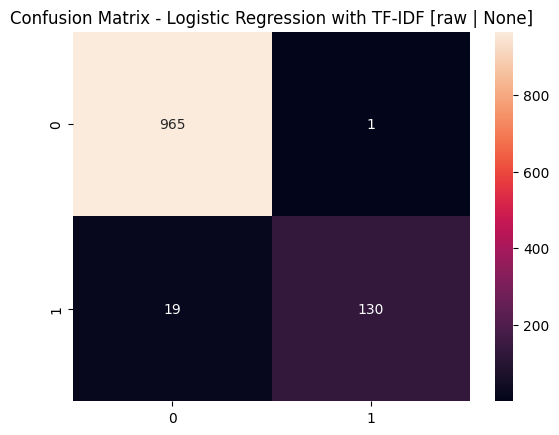


  Tempo de execução do experimento: 9" (0.16') / total: 9" (0.16')

=== Experimento 2: SVM (linear) com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'linear', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.938
      Accuracy: 0.984

  Melhor pontuação (teste):
      F1: 0.937
      Accuracy: 0.984


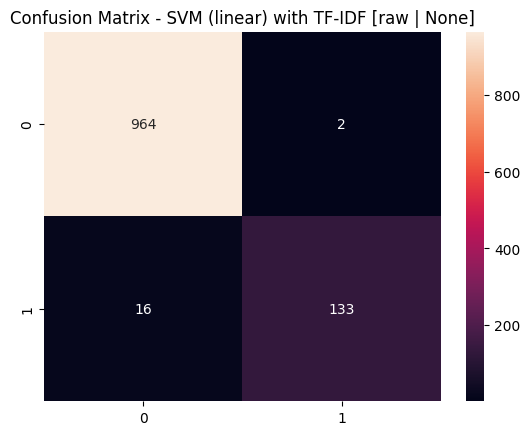


  Tempo de execução do experimento: 99" (1.64') / total: 108" (1.80')

=== Experimento 3: Random Forest com TF-IDF [raw | None] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 1)}

  Melhor pontuação (validação cruzada):
      F1: 0.902
      Accuracy: 0.976

  Melhor pontuação (teste):
      F1: 0.871
      Accuracy: 0.970


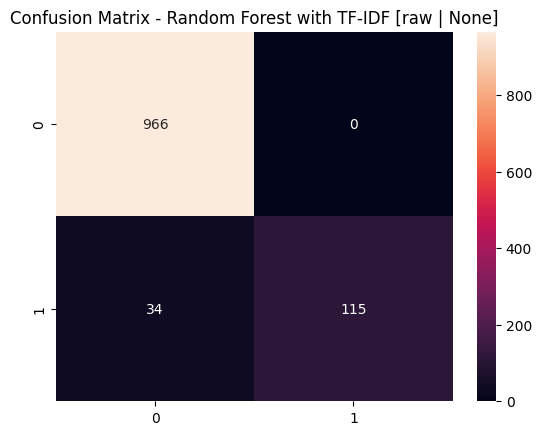


  Tempo de execução do experimento: 107" (1.78') / total: 216" (3.60')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 3
Total de combinações testadas: 60
Total de modelos treinados: 300 (com 5-fold CV)

Tempo total de execução: 216" (3.60')
Tempo médio por experimento: 72" (1.20')


################################################################################
# T1 - TF-IDF (Config A) + reamostragem: SMOTE
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['TF-IDF']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: raw | Reamostragem: SMOTE

=== Experimento 1: Logistic Regression com TF-IDF [raw | SMOTE] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Nú

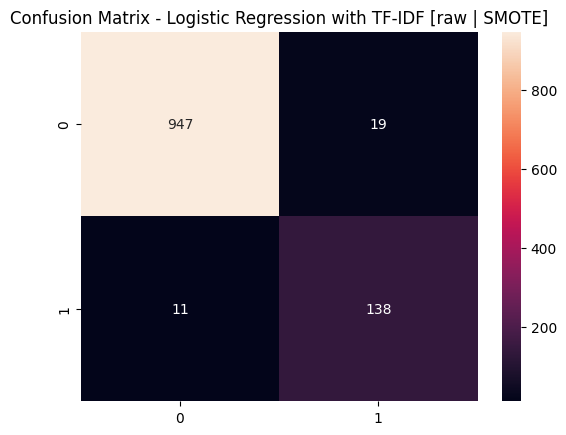


  Tempo de execução do experimento: 9" (0.14') / total: 9" (0.14')

=== Experimento 2: SVM (linear) com TF-IDF [raw | SMOTE] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 0.1, 'clf__kernel': 'linear', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.928
      Accuracy: 0.981

  Melhor pontuação (teste):
      F1: 0.928
      Accuracy: 0.981


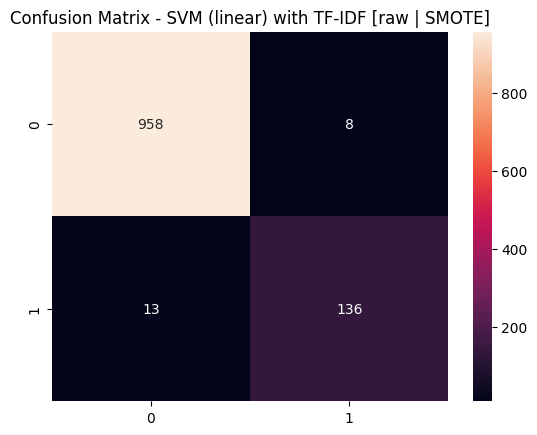


  Tempo de execução do experimento: 199" (3.32') / total: 208" (3.47')

=== Experimento 3: Random Forest com TF-IDF [raw | SMOTE] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.913
      Accuracy: 0.978

  Melhor pontuação (teste):
      F1: 0.929
      Accuracy: 0.982


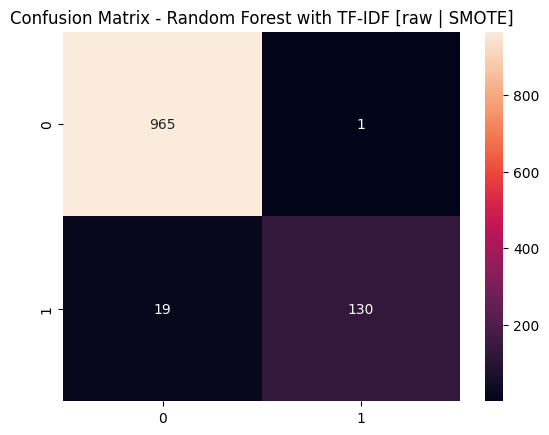


  Tempo de execução do experimento: 156" (2.60') / total: 365" (6.08')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 3
Total de combinações testadas: 60
Total de modelos treinados: 300 (com 5-fold CV)

Tempo total de execução: 365" (6.08')
Tempo médio por experimento: 122" (2.03')


################################################################################
# T1 - TF-IDF (Config A) + reamostragem: RandomUnderSampler
################################################################################
Iniciando experimentos combinando representações de texto e classificadores...
Modelos de representação de texto: ['TF-IDF']
Modelos de classificação: ['Logistic Regression', 'SVM (linear)', 'Random Forest']
Pré-processamento: raw | Reamostragem: RandomUnderSampler

=== Experimento 1: Logistic Regression com TF-IDF [raw | RandomUnderSampler] ===
  Parâmetros a testar (classificador): {'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 've

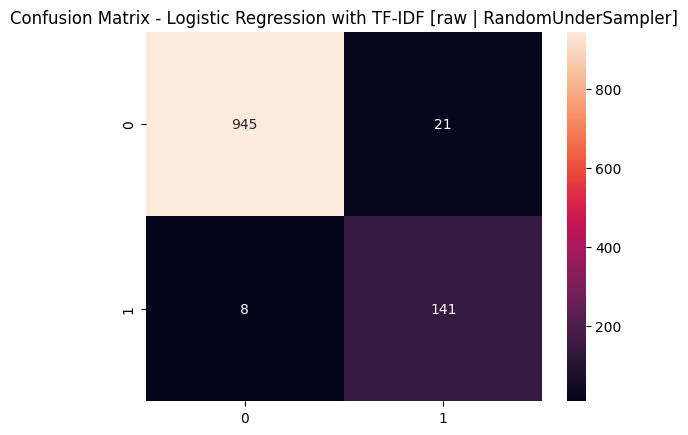


  Tempo de execução do experimento: 8" (0.13') / total: 8" (0.13')

=== Experimento 2: SVM (linear) com TF-IDF [raw | RandomUnderSampler] ===
  Parâmetros a testar (classificador): {'clf__kernel': ['linear', 'rbf'], 'clf__C': (0.1, 1, 10)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'rbf', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.926
      Accuracy: 0.980

  Melhor pontuação (teste):
      F1: 0.920
      Accuracy: 0.978


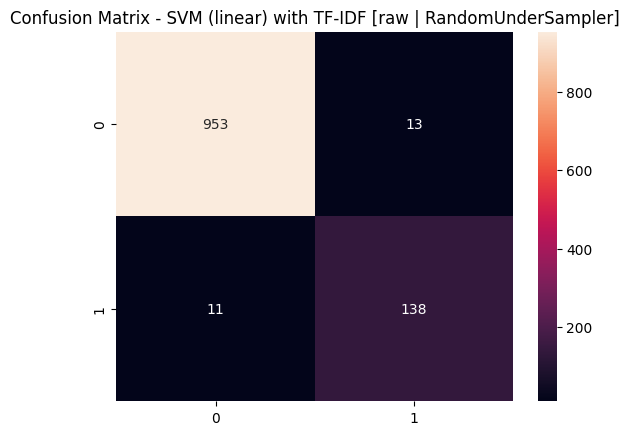


  Tempo de execução do experimento: 30" (0.50') / total: 38" (0.63')

=== Experimento 3: Random Forest com TF-IDF [raw | RandomUnderSampler] ===
  Parâmetros a testar (classificador): {'clf__n_estimators': (100, 200), 'clf__max_depth': (None, 10, 20)}
  Parâmetros a testar (representação): {'vect__max_df': (0.75, 1.0), 'vect__ngram_range': ((1, 1), (1, 2))}
  Número de combinações a testar: 24 (com 5-fold CV = 120 treinos)

  Melhores parâmetros: {'clf__max_depth': None, 'clf__n_estimators': 200, 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

  Melhor pontuação (validação cruzada):
      F1: 0.902
      Accuracy: 0.973

  Melhor pontuação (teste):
      F1: 0.903
      Accuracy: 0.973


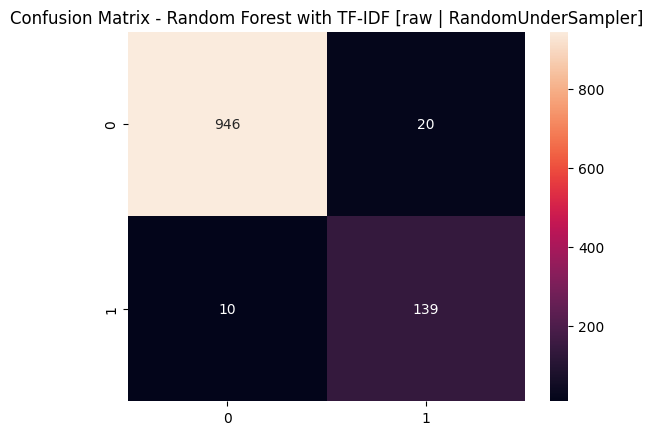


  Tempo de execução do experimento: 68" (1.13') / total: 106" (1.77')

  RESUMO DE TEMPO DE EXECUÇÃO

Total de experimentos: 3
Total de combinações testadas: 60
Total de modelos treinados: 300 (com 5-fold CV)

Tempo total de execução: 106" (1.77')
Tempo médio por experimento: 35" (0.59')


Total de experimentos T1 (reamostragem): 9


In [ ]:
# Representação de referência para a comparação T1: TF-IDF sobre a Config A
# (TF-IDF foi habilitado na Secção 4, garantir que está ativo)
text_representations_tfidf = [rep for rep in text_representations if rep['name'] == 'TF-IDF']
for rep in text_representations_tfidf:
    rep['disable'] = False

# Estratégias de balanceamento a comparar (Tarefa T1)
samplers_t1 = [
    ('None', None),                                # baseline - sem balanceamento
    ('SMOTE', SMOTE(random_state=42)),             # oversampling sintético da classe minoritária (spam)
    ('RandomUnderSampler', RandomUnderSampler(random_state=42)),  # undersampling da classe maioritária (ham)
]

experiments_t1 = []
for sampler_name, sampler_obj in samplers_t1:
    print("\n" + "#"*80)
    print(f"# T1 - TF-IDF (Config A) + reamostragem: {sampler_name}")
    print("#"*80)
    exp = run_experiments(
        text_representations_tfidf, classifiers,
        X_train_A, y_train, X_test_A, y_test,
        sampler=sampler_obj, preprocessing_label='raw'
    )
    experiments_t1.extend(exp)

print(f"\nTotal de experimentos T1 (reamostragem): {len(experiments_t1)}")

## 7. Tabela Comparativa de Resultados

In [ ]:
# Consolidar todos os blocos de experimentos (T1, T2, T3) numa única lista
experiments = experiments_t2 + experiments_t3_emb + experiments_t1

experiments_df = pd.DataFrame(experiments)
experiments_df = experiments_df.sort_values(by='test_f1', ascending=False)
experiments_df.reset_index(drop=True, inplace=True)
print("\n" + "="*60)
print("RESUMO DOS EXPERIMENTOS REALIZADOS")
print("="*60)
display(experiments_df)
print(f"\nTotal de experimentos realizados: {len(experiments)}")

experiments_df.to_csv('exp_completo.csv', index=False)


RESUMO DOS EXPERIMENTOS REALIZADOS


,model,vect,preprocessing,sampler,params,cv_accuracy,cv_f1,test_accuracy,test_f1,num_combinations,execution_time
0,Logistic Regression,BoW,lemm_stop,None,"{'clf__C': 10, 'vect__max_df': 0.5, 'vect__ngr...",0.979807,0.920945,0.984753,0.939929,18,12.495089
1,SVM (linear),TF-IDF,raw,None,"{'clf__C': 1, 'clf__kernel': 'linear', 'vect__...",0.984294,0.938090,0.983857,0.936620,24,104.936519
2,SVM (linear),TF-IDF,raw,None,"{'clf__C': 1, 'clf__kernel': 'linear', 'vect__...",0.984294,0.938090,0.983857,0.936620,24,98.571496
3,Logistic Regression,BoW,raw,None,"{'clf__C': 10, 'vect__max_df': 0.5, 'vect__ngr...",0.981153,0.925952,0.983857,0.936170,18,16.436422
4,SVM (linear),BoW,raw,None,"{'clf__C': 1, 'clf__kernel': 'linear', 'vect__...",0.980031,0.922365,0.982063,0.930556,36,134.102743
5,Logistic Regression,TF-IDF,lemm_stop,None,"{'clf__C': 10, 'vect__max_df': 0.75, 'vect__ng...",0.980031,0.921401,0.982063,0.929078,12,6.433820
6,Logistic Regression,TF-IDF,raw,None,"{'clf__C': 10, 'vect__max_df': 0.75, 'vect__ng...",0.982500,0.931288,0.982063,0.928571,12,10.010570
7,Logistic Regression,TF-IDF,raw,None,"{'clf__C': 10, 'vect__max_df': 0.75, 'vect__ng...",0.982500,0.931288,0.982063,0.928571,12,9.386773
8,Random Forest,TF-IDF,raw,SMOTE,"{'clf__max_depth': None, 'clf__n_estimators': ...",0.978460,0.912939,0.982063,0.928571,24,156.015482
9,SVM (linear),TF-IDF,raw,SMOTE,"{'clf__C': 0.1, 'clf__kernel': 'linear', 'vect...",0.981155,0.928299,0.981166,0.928328,24,199.383583



Total de experimentos realizados: 27


## 8. Visualização Comparativa

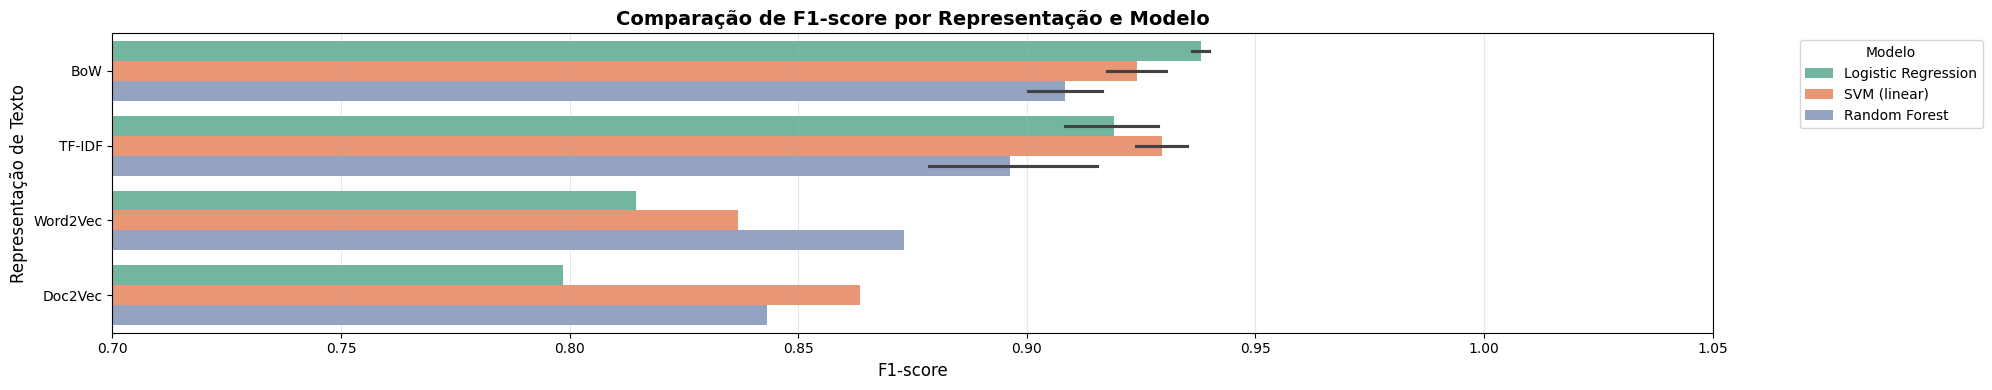

In [ ]:
plt.figure(figsize=(20, 4))
sns.barplot(data=experiments_df, y='vect', x='test_f1', hue='model', palette='Set2', orient='h')
plt.title('Comparação de F1-score por Representação e Modelo', fontsize=14, fontweight='bold')
plt.xlabel('F1-score', fontsize=12)
plt.ylabel('Representação de Texto', fontsize=12)
plt.xlim(0.7, 1.05)
plt.legend(title='Modelo', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Visualização T2 — Impacto do Pré-processamento (Config A vs Config B)

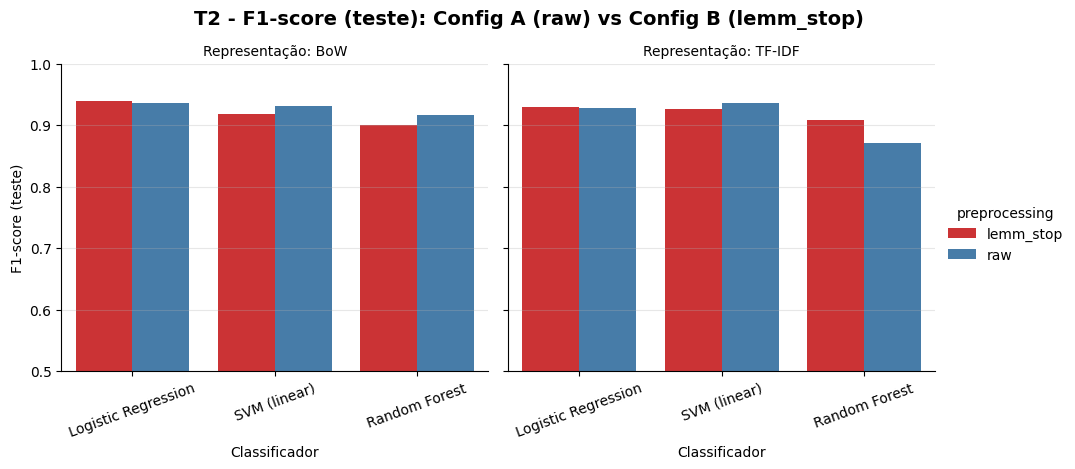

In [ ]:
# Visualização T2: F1-score (teste) - Config A (raw) vs Config B (lemm_stop)
# Apenas BoW/TF-IDF foram testados em ambas as configurações (sem reamostragem)
t2_df = experiments_df[
    (experiments_df['sampler'] == 'None') &
    (experiments_df['vect'].isin(['BoW', 'TF-IDF']))
].copy()

g = sns.catplot(
    data=t2_df, x='model', y='test_f1', hue='preprocessing',
    col='vect', kind='bar', palette='Set1', height=4, aspect=1.2
)
g.set_axis_labels('Classificador', 'F1-score (teste)')
g.set_titles('Representação: {col_name}')
for ax in g.axes.flat:
    ax.set_ylim(0.5, 1.0)
    ax.tick_params(axis='x', rotation=20)
    ax.grid(axis='y', alpha=0.3)
g.fig.suptitle('T2 - F1-score (teste): Config A (raw) vs Config B (lemm_stop)',
               fontsize=14, fontweight='bold', y=1.05)
plt.show()

### Visualização T1 — Impacto do Balanceamento de Classes (SMOTE / RandomUnderSampler)

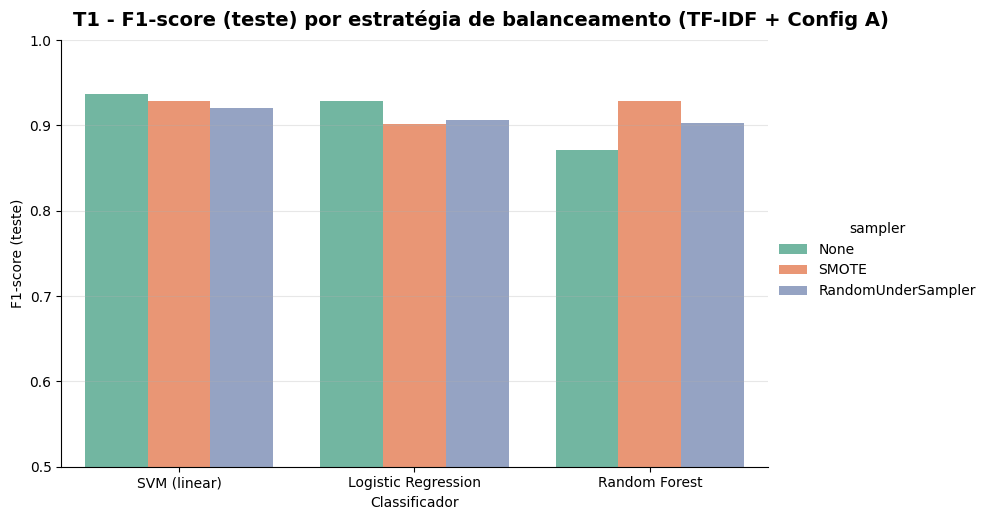

In [ ]:
# Visualização T1: F1-score (teste) por estratégia de balanceamento
# (TF-IDF + Config B, os 3 classificadores)
t1_df = experiments_df[
    (experiments_df['vect'] == 'TF-IDF') &
    (experiments_df['preprocessing'] == 'raw')
].copy()

g = sns.catplot(
    data=t1_df, x='model', y='test_f1', hue='sampler',
    kind='bar', palette='Set2', height=5, aspect=1.6
)
g.set_axis_labels('Classificador', 'F1-score (teste)')
g.fig.suptitle('T1 - F1-score (teste) por estratégia de balanceamento (TF-IDF + Config A)',
               fontsize=14, fontweight='bold', y=1.03)
for ax in g.axes.flat:
    ax.set_ylim(0.5, 1.0)
    ax.grid(axis='y', alpha=0.3)
plt.show()

## 9. Análise de overfiting: comparação CV vs test (F1)

In [ ]:
# Calcular diferenças
experiments_df['diff_accuracy'] = experiments_df['test_accuracy'] - experiments_df['cv_accuracy']
experiments_df['diff_f1'] = experiments_df['test_f1'] - experiments_df['cv_f1']

# Estatísticas das diferenças
print("\nEstatísticas das Diferenças (Test - CV):\n")

print(f"   ACCURACY:")
print(f"      Diferença média: {experiments_df['diff_accuracy'].mean():.4f}")
print(f"      Diferença mín:   {experiments_df['diff_accuracy'].min():.4f}")
print(f"      Diferença máx:   {experiments_df['diff_accuracy'].max():.4f}")
print(f"      Desvio padrão:   {experiments_df['diff_accuracy'].std():.4f}")

print(f"\n   F1-SCORE:")
print(f"      Diferença média: {experiments_df['diff_f1'].mean():.4f}")
print(f"      Diferença mín:   {experiments_df['diff_f1'].min():.4f}")
print(f"      Diferença máx:   {experiments_df['diff_f1'].max():.4f}")
print(f"      Desvio padrão:   {experiments_df['diff_f1'].std():.4f}")

# Classificar overfitting
print(f"\n    Classificação de Overfitting:\n")

# Overfitting grave: diferença > 0.05
overfit_threshold = 0.05
overfit_count = ((experiments_df['diff_accuracy'].abs() > overfit_threshold) |
                 (experiments_df['diff_f1'].abs() > overfit_threshold)).sum()

if overfit_count == 0:
    print(f"       Sem overfitting detectado!")
    print(f"       (Todas as diferenças CV-Test < {overfit_threshold})")
else:
    print(f"        {overfit_count} combinação(ões) com possível overfitting:")
    overfit_cases = experiments_df[
        ((experiments_df['diff_accuracy'].abs() > overfit_threshold) |
         (experiments_df['diff_f1'].abs() > overfit_threshold))
    ][['model', 'vect', 'diff_accuracy', 'diff_f1']]
    for idx, row in overfit_cases.iterrows():
        print(f"         • {row['model']:20s} + {row['vect']:10s}: " +
              f"Δ Accuracy = {row['diff_accuracy']:+.4f}, Δ F1 = {row['diff_f1']:+.4f}")


Estatísticas das Diferenças (Test - CV):

   ACCURACY:
      Diferença média: 0.0004
      Diferença mín:   -0.0166
      Diferença máx:   0.0184
      Desvio padrão:   0.0068

   F1-SCORE:
      Diferença média: 0.0016
      Diferença mín:   -0.0763
      Diferença máx:   0.0939
      Desvio padrão:   0.0321

    Classificação de Overfitting:

        3 combinação(ões) com possível overfitting:
         • SVM (linear)         + Word2Vec  : Δ Accuracy = +0.0155, Δ F1 = +0.0732
         • Logistic Regression  + Word2Vec  : Δ Accuracy = +0.0184, Δ F1 = +0.0939
         • Logistic Regression  + Doc2Vec   : Δ Accuracy = -0.0166, Δ F1 = -0.0763


## 10. Análise de Erros (Tarefa T5)

Esta secção seleciona o **melhor modelo** da tabela comparativa, treina-o nos dados de treino correspondentes, e analisa os erros de classificação no conjunto de teste:

- **Falsos Negativos (FN)**: mensagens *spam* classificadas como *ham*.
- **Falsos Positivos (FP)**: mensagens *ham* classificadas como *spam*.

Para cada tipo de erro, são apresentados exemplos concretos com o **texto original** da mensagem (antes do pré-processamento), seguidos de uma discussão dos padrões observados.

Melhores parâmetros: {'clf__C': 1, 'clf__kernel': 'linear', 'vect__max_df': 0.75, 'vect__ngram_range': (1, 2)}

Matriz de confusão (melhor modelo):


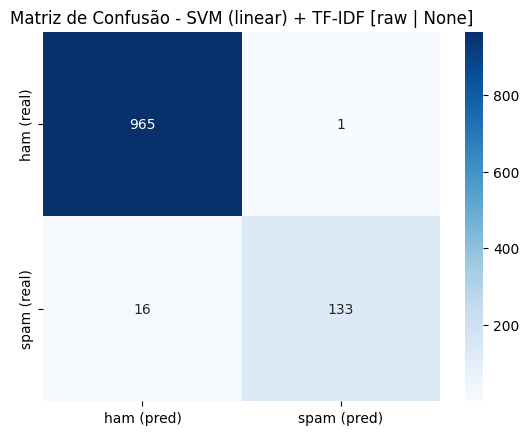

In [ ]:
# Melhor configuração (já decidida manualmente: SVM linear + TF-IDF + Config A)
best_params = experiments_df[
    (experiments_df['model'] == 'SVM (linear)') &
    (experiments_df['vect'] == 'TF-IDF') &
    (experiments_df['preprocessing'] == 'raw') &
    (experiments_df['sampler'] == 'None')
].iloc[0]['params']

print("Melhores parâmetros:", best_params)

best_pipeline = Pipeline([
    ('vect', TfidfVectorizer(min_df=2, max_features=3000)),
    ('clf', SVC(random_state=42))
])
best_pipeline.set_params(**best_params)
best_pipeline.fit(X_train_A, y_train)
y_pred_best = best_pipeline.predict(X_test_A)

print("\nMatriz de confusão (melhor modelo):")
cm_best = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues',
            xticklabels=['ham (pred)', 'spam (pred)'],
            yticklabels=['ham (real)', 'spam (real)'])
plt.title(f"Matriz de Confusão - SVM (linear) + TF-IDF [raw | None]")
plt.show()

In [ ]:
# Identificar Falsos Negativos (spam -> ham) e Falsos Positivos (ham -> spam)
results_test = pd.DataFrame({
    'message': df.loc[X_test_A.index, 'message'].values,
    'y_true': y_test.values,
    'y_pred': y_pred_best
}, index=X_test_A.index)

false_negatives = results_test[(results_test['y_true'] == 1) & (results_test['y_pred'] == 0)]
false_positives = results_test[(results_test['y_true'] == 0) & (results_test['y_pred'] == 1)]

print(f"Total de Falsos Negativos (spam classificado como ham): {len(false_negatives)}")
print(f"Total de Falsos Positivos (ham classificado como spam): {len(false_positives)}")
print(f"Recall da classe spam (1 - taxa de FN): {1 - len(false_negatives) / y_test.sum():.2%}")

Total de Falsos Negativos (spam classificado como ham): 16
Total de Falsos Positivos (ham classificado como spam): 1
Recall da classe spam (1 - taxa de FN): 89.26%


In [ ]:
print("\n" + "="*70)
print("FALSOS NEGATIVOS - spam classificado como ham (exemplos)")
print("="*70)
if len(false_negatives) == 0:
    print("  (nenhum falso negativo encontrado neste modelo/conjunto de teste)")
else:
    for i, (idx, row) in enumerate(false_negatives.head(10).iterrows()):
        print(f"\n  [{i+1}] (índice {idx})")
        print(f"      Mensagem original: {row['message']}")

print("\n" + "="*70)
print("FALSOS POSITIVOS - ham classificado como spam (exemplos)")
print("="*70)
if len(false_positives) == 0:
    print("  (nenhum falso positivo encontrado neste modelo/conjunto de teste)")
else:
    for i, (idx, row) in enumerate(false_positives.head(10).iterrows()):
        print(f"\n  [{i+1}] (índice {idx})")
        print(f"      Mensagem original: {row['message']}")


FALSOS NEGATIVOS - spam classificado como ham (exemplos)

  [1] (índice 5)
      Mensagem original: FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv

  [2] (índice 1663)
      Mensagem original: Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 JANINExx Calls£1/minMobsmoreLKPOBOX177HP51FL

  [3] (índice 3981)
      Mensagem original: ringtoneking 84484

  [4] (índice 3360)
      Mensagem original: Sorry I missed your call let's talk when you have the time. I'm on 07090201529

  [5] (índice 5449)
      Mensagem original: Latest News! Police station toilet stolen, cops have nothing to go on!

  [6] (índice 3755)
      Mensagem original: Bloomberg -Message center +447797706009 Why wait? Apply for your future http://careers. bloomberg.com

  [7] (índice 1269)
      Mensagem original: Can U get 2 phone NOW? I wanna chat 2 set up

### Discussão dos Padrões de Erro

O melhor modelo encontrado foi **SVM (linear) + TF-IDF + Config A (raw)**, com hiperparâmetros `C=1`, `kernel='linear'`, `max_df=0.75`, `ngram_range=(1,2)`. No conjunto de teste (1115 mensagens: 966 ham, 149 spam), a matriz de confusão foi:

|               | ham (pred) | spam (pred) |
|---|---|---|
| **ham (real)**  | 965 | 1 |
| **spam (real)** | 16  | 133 |

Isto dá uma precisão muito elevada na classe spam (133/134 = 99.25%) mas um recall mais modesto (133/149 = 89.26%).


**Falsos Negativos (16 mensagens de spam não detetadas):**

O padrão dominante nestes exemplos é, sobretudo, um efeito da função `clean_text`, que remove **todos os dígitos e símbolos** (`re.sub(r'[^a-zA-Z\s]', '', text)`) em ambas as configurações (A e B). Isto elimina por completo precisamente os sinais mais fortes e inequívocos de spam neste dataset:

- **Preços e tarifas desaparecem por completo.** Em "*FreeMsg Hey there darling... std chgs to send, £1.50 to rcv*", o valor `£1.50` é totalmente removido, restando só a linguagem casual/afetuosa ("darling", "fun"), que imita o tom de uma mensagem pessoal.
- **Números de telefone e códigos desaparecem.** Em "*...Calls£1/minmoremobsEMSPOBox45PO139WA*" e em "*09099726429 JANINExx*", os números são removidos, deixando apenas fragmentos de texto sem sentido que não correspondem a nenhum termo útil do vocabulário.
- **URLs ficam ilegíveis.** "*http://careers.bloomberg.com*" perde toda a pontuação estrutural (`.`, `/`, `:`) sem inserir espaço a substituir, colando-se num único token sem sentido (`httpcareersbloombergcom`), que muito provavelmente nunca aparece no vocabulário de treino.
- **Mensagens muito curtas perdem o único sinal que tinham.** "*ringtoneking 84484*" fica reduzida a uma única palavra ("ringtoneking") depois de o número ser removido — e, sendo um termo muito raro, é provável que nem sobreviva ao filtro `min_df=2` definido na Secção 4. É o exemplo mais extremo de perda de informação por pré-processamento.
- **Ortografia deliberadamente alterada para evadir filtros**: "*Low-cost prescripiton drvgs*" usa erros ortográficos propositados ("prescripiton", "drvgs") — uma técnica clássica de spammers para escapar a filtros baseados em palavras-chave exatas. Como estas variantes são, por definição, raras, o `min_df=2` tende a excluí-las do vocabulário, tornando este tipo de spam praticamente invisível ao modelo.
